# Load Packages

In [80]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [81]:
import sys
sys.path.append('../src')

In [82]:
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import umap

In [83]:
from data_loading import *
from eda import *
from data_cleaning import *
from k_means import *
from cluster_evaluation import *
from cluster_interpretation import *

In [84]:
import hdbscan

# Load Data for Clustering

In [85]:
embeddings_numpy_arr = np.load("../data/analysis_data/embeddings.npy")
embeddings_df = pd.DataFrame(embeddings_numpy_arr)

In [86]:
path = "../data/analysis_data/only_english.csv"
only_english = read_file(path, seperator=",")
only_english = only_english[['product_name', 'categories_tags', 'nova_group', 'ingredients_text', 'ingredient_count', 'additives_n', 'nutriscore_score', 'monounsaturated-fat_100g','sugars_100g','polyunsaturated-fat_100g','sugar_fiber_ratio','carbohydrates_100g','fiber_100g','saturated-fat_100g','sodium_per_calorie']]
# only_english = only_english[['product_name', 'categories_tags', 'nova_group', 'ingredients_text']]
print(only_english.shape)
only_english.head()

Shape of the data: (272809, 18)

Columns loaded:
['code', 'product_name', 'categories_tags', 'ingredients_text', 'ingredient_count', 'additives_n', 'additive_density', 'nutriscore_score', 'monounsaturated-fat_100g', 'sugars_100g', 'polyunsaturated-fat_100g', 'sugar_fiber_ratio', 'carbohydrates_100g', 'fiber_100g', 'saturated-fat_100g', 'sodium_per_calorie', 'allergens_en', 'nova_group']
(272809, 15)


,product_name,categories_tags,nova_group,ingredients_text,ingredient_count,additives_n,nutriscore_score,monounsaturated-fat_100g,sugars_100g,polyunsaturated-fat_100g,sugar_fiber_ratio,carbohydrates_100g,fiber_100g,saturated-fat_100g,sodium_per_calorie
0,Hershey’s Syrup,"en:beverages-and-beverages-preparations,en:bev...",1,organ defat hemp seed powder certifi organ qua...,1,0.0,NaN,0.0,6.0,0.0,0.594059,15.00,10.000,0.0,NaN
1,Vanille-Erdbeer-Cocktail,NaN,4,sunflow seed butter roast sunflow kernel dri c...,30,4.0,NaN,0.0,0.0,0.0,NaN,8.82,0.441,0.0,NaN
2,Naturelo,NaN,4,methylcellulos color preserv flavong ount per ...,5,1.0,NaN,0.0,0.0,0.0,NaN,0.00,0.000,0.0,NaN
3,Prebiotic Fiber Gummies,"en:snacks,en:sweet-snacks,en:confectioneries,e...",4,chicori root fiber water pectin agar agar tapi...,11,6.0,NaN,0.0,0.0,0.0,NaN,0.00,0.000,0.0,NaN
4,Irish Sea Moss,NaN,4,irish sea moss extract chondru crispu hypromel...,3,2.0,NaN,0.0,0.0,0.0,NaN,0.00,0.000,0.0,NaN


In [87]:
cluster_df = merge_data_frames(df1=only_english, df2 = embeddings_df)
cluster_df.head()

,product_name,categories_tags,nova_group,ingredients_text,ingredient_count,additives_n,nutriscore_score,monounsaturated-fat_100g,sugars_100g,polyunsaturated-fat_100g,...,374,375,376,377,378,379,380,381,382,383
0,Hershey’s Syrup,"en:beverages-and-beverages-preparations,en:bev...",1,organ defat hemp seed powder certifi organ qua...,1,0.0,NaN,0.0,6.0,0.0,...,-0.021125,0.020245,0.064699,-0.034334,0.051692,-0.022212,0.006391,0.025445,0.077194,-0.048097
1,Vanille-Erdbeer-Cocktail,NaN,4,sunflow seed butter roast sunflow kernel dri c...,30,4.0,NaN,0.0,0.0,0.0,...,-0.002987,0.008882,0.038631,-0.054230,0.064427,-0.033297,-0.031501,-0.038130,-0.006603,-0.042481
2,Naturelo,NaN,4,methylcellulos color preserv flavong ount per ...,5,1.0,NaN,0.0,0.0,0.0,...,-0.073252,0.015455,0.074647,0.074792,0.046393,-0.074582,-0.020494,-0.082925,0.045365,-0.041050
3,Prebiotic Fiber Gummies,"en:snacks,en:sweet-snacks,en:confectioneries,e...",4,chicori root fiber water pectin agar agar tapi...,11,6.0,NaN,0.0,0.0,0.0,...,0.057201,0.003271,0.063289,0.023518,0.026960,0.024571,-0.015965,-0.011356,0.067122,-0.004868
4,Irish Sea Moss,NaN,4,irish sea moss extract chondru crispu hypromel...,3,2.0,NaN,0.0,0.0,0.0,...,-0.035997,0.041002,0.092975,-0.031187,0.005940,-0.003002,-0.091133,-0.081211,0.068467,0.013320


# Dimension Reduction

In [41]:
# creat random sampling of 20k samples for clustering analysis
SAMPLE_SIZE = 20000
cluster_df_sample = cluster_df.groupby('nova_group', group_keys=False).apply(lambda x: x.sample(min(len(x), int(SAMPLE_SIZE * len(x) / len(cluster_df))), random_state=42)).reset_index(drop=True)
working_df = cluster_df_sample

/var/folders/7j/pj2q5pdx6g373n0pxkk0xd4r0000gn/T/ipykernel_88742/3866606337.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cluster_df_sample = cluster_df.groupby('nova_group', group_keys=False).apply(lambda x: x.sample(min(len(x), int(SAMPLE_SIZE * len(x) / len(cluster_df))), random_state=42)).reset_index(drop=True)


In [42]:
print(cluster_df['nova_group'].value_counts())
print(working_df['nova_group'].value_counts())

nova_group
4    214017
3     40891
1     16166
2      1735
Name: count, dtype: int64
nova_group
4    15689
3     2997
1     1185
2      127
Name: count, dtype: int64


In [85]:
# find best reduction
dims = [25, 50, 75, 100, 125, 150, 175]
results_umap = {
        "number_of_dimensions": [],
        "inertia": [],
        "silhouette": [],
        "davies_bouldin": [],
        "calinski_harabasz": []
    }
embeddings, df_meta = extract_embeddings(working_df)
for i in dims:
    
    embeddings_umap, _ = reduce_dimensions_umap(embeddings, n_components=i, random_state=42)
    
    k = 30
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(embeddings_umap)

    # store metrics
    results_umap["number_of_dimensions"].append(i)
    results_umap["silhouette"].append(silhouette_score(embeddings_umap, labels))
    results_umap["davies_bouldin"].append(davies_bouldin_score(embeddings_umap, labels))
    results_umap["calinski_harabasz"].append(calinski_harabasz_score(embeddings_umap, labels))







Reducing from 384 to 25 dimensions using UMAP
UMAP(angular_rp_forest=True, metric='cosine', n_components=25, n_jobs=1, random_state=42, verbose=True)
Thu Nov 27 18:02:54 2025 Construct fuzzy simplicial set
Thu Nov 27 18:02:54 2025 Finding Nearest Neighbors
Thu Nov 27 18:02:54 2025 Building RP forest with 12 trees


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Thu Nov 27 18:02:54 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	 5  /  14
	Stopping threshold met -- exiting after 5 iterations
Thu Nov 27 18:02:57 2025 Finished Nearest Neighbor Search
Thu Nov 27 18:02:57 2025 Construct embedding


Epochs completed:   4%| ▍          8/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  12%| █▏         23/200 [00:01]

... (159 outputs left out)

Epochs completed:  90%| █████████  181/200 [00:38]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:42]


Thu Nov 27 18:07:58 2025 Finished embedding
UMAP reduction complete: (19998, 175)


In [94]:
dic = results_umap

pd.DataFrame(dic)

,number_of_dimensions,silhouette,davies_bouldin,calinski_harabasz
0,25,0.413343,0.643320,8402.884766
1,50,0.408086,0.715384,7308.663574
2,75,0.376225,0.711142,7005.805664
3,100,0.397145,0.639864,7069.215820
4,125,0.384668,0.697242,7245.410156
5,150,0.413819,0.626282,7109.308105
6,175,0.406262,0.624468,7173.805176


In [95]:
embeddings, df_meta = extract_embeddings(working_df)
embeddings_umap, _ = reduce_dimensions_umap(embeddings, n_components=150, random_state=42)
# embeddings_umap = embeddings


Reducing from 384 to 150 dimensions using UMAP
UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Thu Nov 27 18:10:45 2025 Construct fuzzy simplicial set
Thu Nov 27 18:10:45 2025 Finding Nearest Neighbors
Thu Nov 27 18:10:45 2025 Building RP forest with 12 trees


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Thu Nov 27 18:10:45 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	 5  /  14
	Stopping threshold met -- exiting after 5 iterations
Thu Nov 27 18:10:48 2025 Finished Nearest Neighbor Search
Thu Nov 27 18:10:48 2025 Construct embedding


Epochs completed:   2%| ▎          5/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  11%| █          22/200 [00:03]

... (15 outputs left out)

Epochs completed:  91%| █████████  182/200 [00:32]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:36]


Thu Nov 27 18:11:34 2025 Finished embedding
UMAP reduction complete: (19998, 150)


# K Means Experiment with 20k samples

In [59]:


Ks = range(10, 201, 10)   # example: 5 → 100 clusters in steps of 5
results = {
    "k": [],
    "inertia": [],
    "silhouette": [],
    "davies_bouldin": [],
    "calinski_harabasz": []
}

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(embeddings_umap)

    # store metrics
    results["k"].append(k)
    results["inertia"].append(kmeans.inertia_)
    results["silhouette"].append(silhouette_score(embeddings_umap, labels))
    results["davies_bouldin"].append(davies_bouldin_score(embeddings_umap, labels))
    results["calinski_harabasz"].append(calinski_harabasz_score(embeddings_umap, labels))




In [62]:
pd.DataFrame(results)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,10,95008.625000,0.340302,0.859599,5264.390625
1,20,48287.875000,0.402520,0.748473,5921.292969
2,30,28275.222656,0.413819,0.626282,7109.308105
3,40,19590.324219,0.379233,0.670948,7853.058105
4,50,14483.234375,0.400329,0.640332,8593.736328
5,60,11333.239258,0.379747,0.718880,9210.258789
6,70,9412.458984,0.386931,0.693559,9536.737305
7,80,7840.385742,0.399066,0.684969,10045.246094
8,90,6739.368652,0.396467,0.745978,10404.607422
9,100,5991.190918,0.397752,0.749927,10541.528320


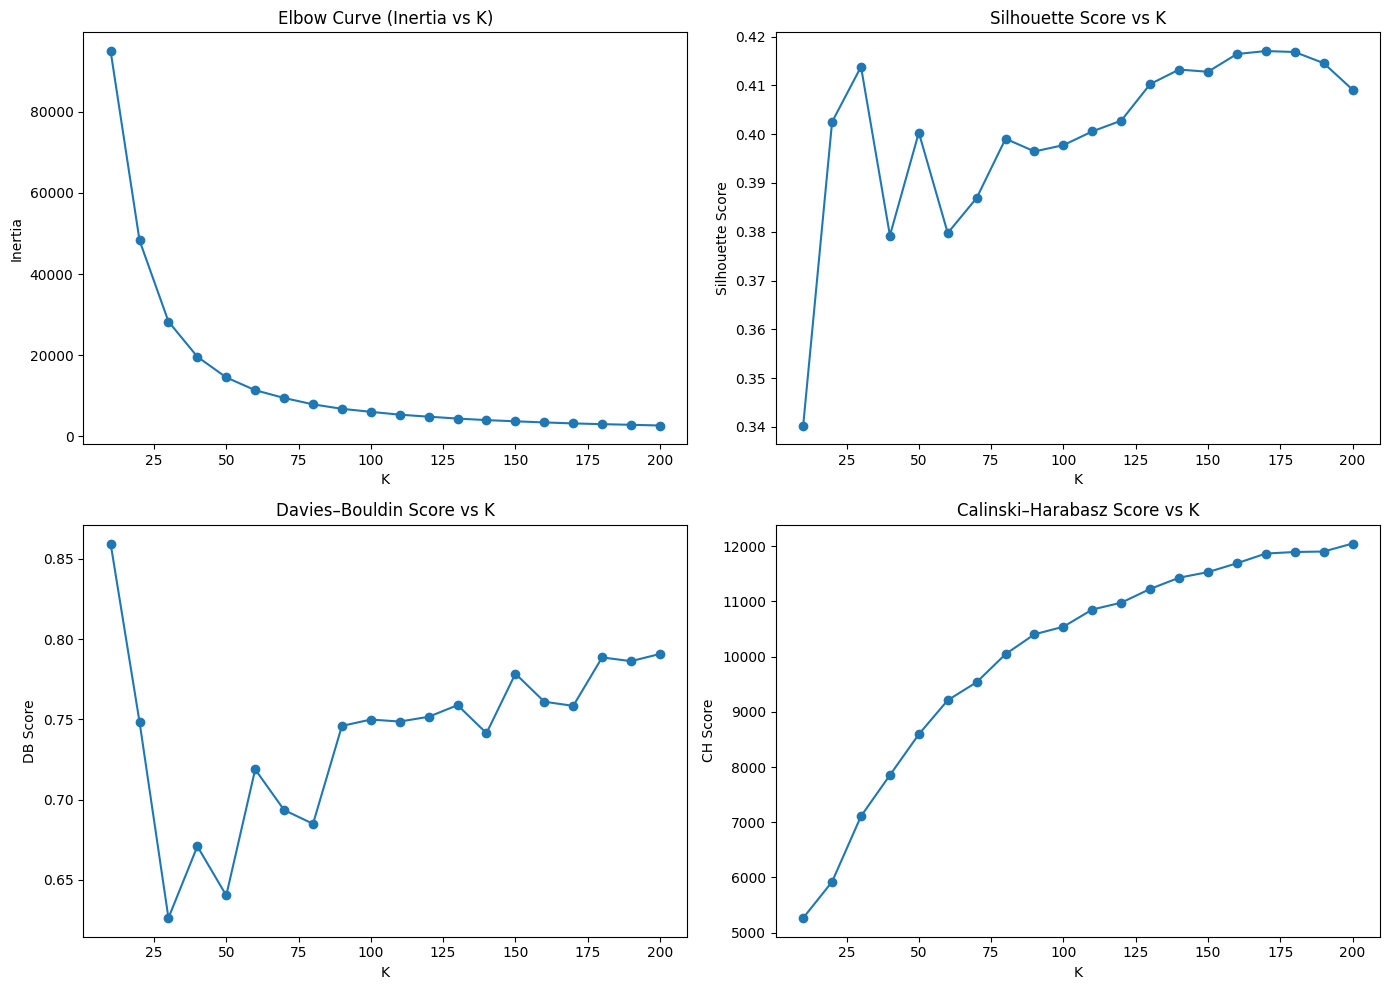

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# 1. Elbow curve (inertia)
plt.subplot(2, 2, 1)
plt.plot(results["k"], results["inertia"], marker='o')
plt.title("Elbow Curve (Inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")

# 2. Silhouette score
plt.subplot(2, 2, 2)
plt.plot(results["k"], results["silhouette"], marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")

# 3. Davies-Bouldin (lower is better)
plt.subplot(2, 2, 3)
plt.plot(results["k"], results["davies_bouldin"], marker='o')
plt.title("Davies–Bouldin Score vs K")
plt.xlabel("K")
plt.ylabel("DB Score")

# 4. Calinski–Harabasz (higher is better)
plt.subplot(2, 2, 4)
plt.plot(results["k"], results["calinski_harabasz"], marker='o')
plt.title("Calinski–Harabasz Score vs K")
plt.xlabel("K")
plt.ylabel("CH Score")

plt.tight_layout()
plt.show()


# Hierarchial Experiments with 20k samples

In [63]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np

Ks = range(5, 101, 10)  # customize as needed

results_hier = {
    "k": [],
    "silhouette": [],
    "davies_bouldin": [],
    "calinski_harabasz": []
}

for k in Ks:
    hier = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = hier.fit_predict(embeddings_umap)

    # Store metrics
    results_hier["k"].append(k)
    results_hier["silhouette"].append(silhouette_score(embeddings_umap, labels))
    results_hier["davies_bouldin"].append(davies_bouldin_score(embeddings_umap, labels))
    results_hier["calinski_harabasz"].append(calinski_harabasz_score(embeddings_umap, labels))

print("Done computing Hierarchical metrics for all K!")


Done computing Hierarchical metrics for all K!


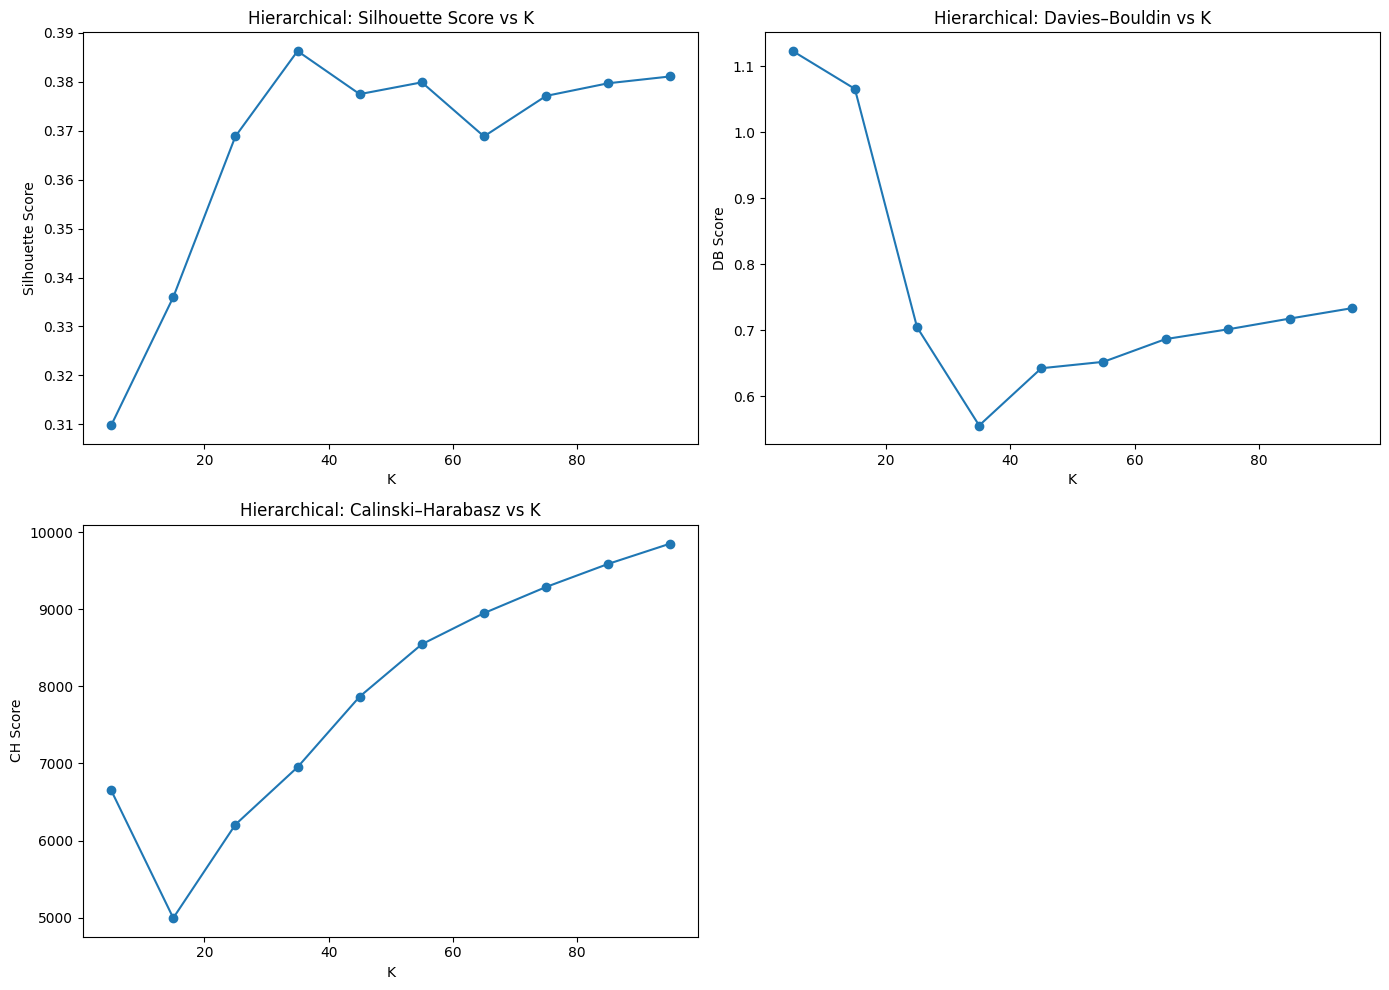

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# Silhouette
plt.subplot(2, 2, 1)
plt.plot(results_hier["k"], results_hier["silhouette"], marker='o')
plt.title("Hierarchical: Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")

# Davies–Bouldin (lower is better)
plt.subplot(2, 2, 2)
plt.plot(results_hier["k"], results_hier["davies_bouldin"], marker='o')
plt.title("Hierarchical: Davies–Bouldin vs K")
plt.xlabel("K")
plt.ylabel("DB Score")

# Calinski–Harabasz (higher is better)
plt.subplot(2, 2, 3)
plt.plot(results_hier["k"], results_hier["calinski_harabasz"], marker='o')
plt.title("Hierarchical: Calinski–Harabasz vs K")
plt.xlabel("K")
plt.ylabel("CH Score")

plt.tight_layout()
plt.show()


# GMM Experiments with 20k samples

In [180]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np

Ks = range(5, 106, 10)  # choose any range you prefer

results_gmm = {
    "k": [],
    "bic": [],
    "aic": [],
    "silhouette": [],
    "davies_bouldin": [],
    "calinski_harabasz": []
}

for k in Ks:
    try:
        gmm = GaussianMixture(
            n_components=k,
            random_state=42,
            covariance_type='diag',  # <-- DIAGONAL COVARIANCE
            reg_covar=1e-3           # <-- small regularization for stability
        )

        labels = gmm.fit_predict(embeddings_umap)

        # Store K
        results_gmm["k"].append(k)

        # Store metrics
        results_gmm["bic"].append(gmm.bic(embeddings_umap))
        results_gmm["aic"].append(gmm.aic(embeddings_umap))
        results_gmm["silhouette"].append(silhouette_score(embeddings_umap, labels))
        results_gmm["davies_bouldin"].append(davies_bouldin_score(embeddings_umap, labels))
        results_gmm["calinski_harabasz"].append(calinski_harabasz_score(embeddings_umap, labels))

        print(f"K={k} succeeded")

    except Exception as e:
        print(f"K={k} failed: {e}")


K=5 succeeded
K=15 succeeded
K=25 succeeded
K=35 succeeded
K=45 succeeded
K=55 succeeded
K=65 succeeded
K=75 succeeded
K=85 succeeded
K=95 succeeded
K=105 succeeded


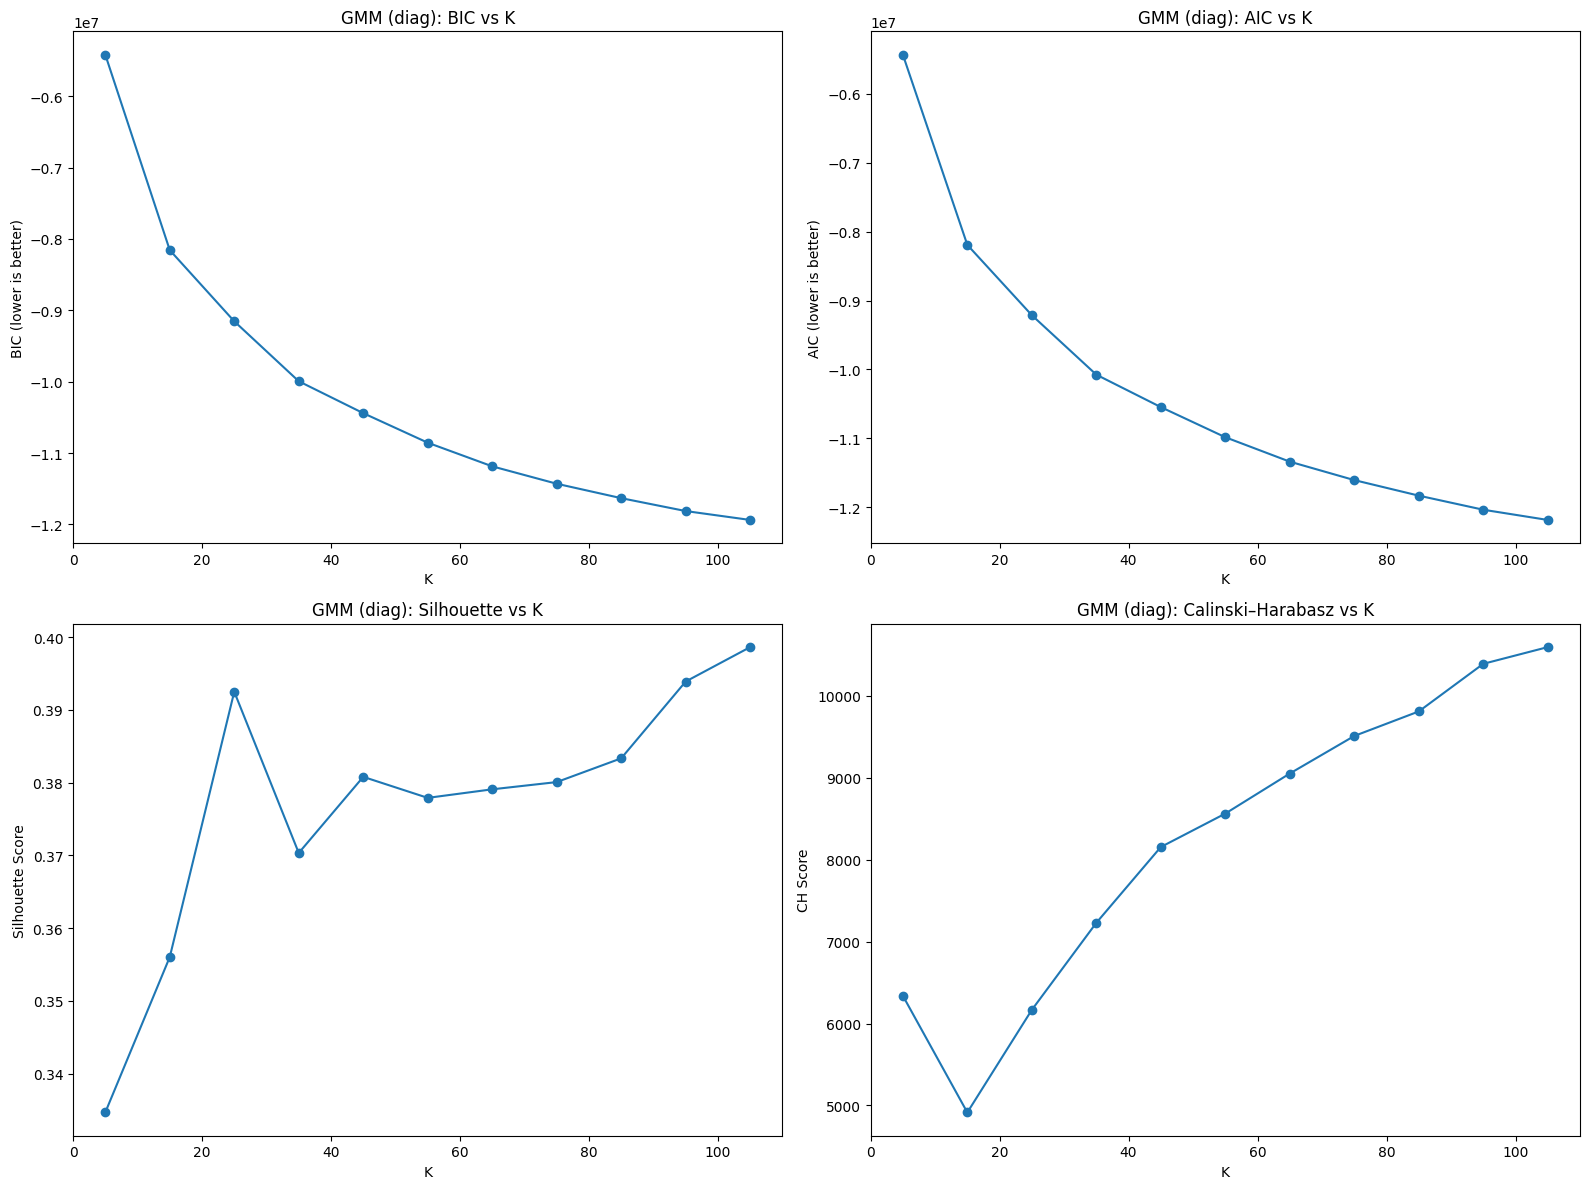

In [183]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

# BIC
plt.subplot(2, 2, 1)
plt.plot(results_gmm["k"], results_gmm["bic"], marker='o')
plt.title("GMM (diag): BIC vs K")
plt.xlabel("K")
plt.ylabel("BIC (lower is better)")

# AIC
plt.subplot(2, 2, 2)
plt.plot(results_gmm["k"], results_gmm["aic"], marker='o')
plt.title("GMM (diag): AIC vs K")
plt.xlabel("K")
plt.ylabel("AIC (lower is better)")

# Silhouette
plt.subplot(2, 2, 3)
plt.plot(results_gmm["k"], results_gmm["silhouette"], marker='o')
plt.title("GMM (diag): Silhouette vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")

# Calinski–Harabasz
plt.subplot(2, 2, 4)
plt.plot(results_gmm["k"], results_gmm["calinski_harabasz"], marker='o')
plt.title("GMM (diag): Calinski–Harabasz vs K")
plt.xlabel("K")
plt.ylabel("CH Score")

plt.tight_layout()
plt.show()


# HDBSCAN wxperiment with 20k samples

In [ ]:
# --- 1. Sample embeddings (20k max) ---
sample_size = min(20000, embeddings_umap.shape[0])  # use full data if <20k
idx = np.random.choice(range(embeddings_umap.shape[0]), size=sample_size, replace=False)
embeddings_sample = embeddings_umap[idx]

# --- 2. Define range of min_cluster_size to try ---
min_cluster_sizes = range(50, 1001, 50)  # adjust as needed

# --- 3. Prepare results dict ---
results_hdb = {
    "min_cluster_size": [],
    "n_clusters": [],
    "n_noise": [],
    "silhouette": [],
    "davies_bouldin": [],
    "calinski_harabasz": []
}

# --- 4. Run HDBSCAN for each min_cluster_size ---
for mcs in min_cluster_sizes:
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=mcs,
        metric='euclidean',       # or 'cosine' if embeddings are normalized
        cluster_selection_method='eom'
    )
    
    labels = clusterer.fit_predict(embeddings_sample)
    
    # Number of clusters (exclude noise)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)
    
    # Filter out noise for metrics
    mask = labels != -1
    if mask.sum() == 0 or n_clusters == 0:
        sil = db = ch = np.nan
    else:
        sil = silhouette_score(embeddings_sample[mask], labels[mask])
        db = davies_bouldin_score(embeddings_sample[mask], labels[mask])
        ch = calinski_harabasz_score(embeddings_sample[mask], labels[mask])
    
    # Store results
    results_hdb["min_cluster_size"].append(mcs)
    results_hdb["n_clusters"].append(n_clusters)
    results_hdb["n_noise"].append(n_noise)
    results_hdb["silhouette"].append(sil)
    results_hdb["davies_bouldin"].append(db)
    results_hdb["calinski_harabasz"].append(ch)

# --- 5. Convert to DataFrame for inspection ---
results_hdb_df = pd.DataFrame(results_hdb)
print(results_hdb_df)

# Comparison of experiments

In [96]:
kmeans_results = pd.DataFrame(results)
hierarchial_results = pd.DataFrame(results_hier)
gmm_results = pd.DataFrame(results_gmm)

In [99]:
print("kmeans")
print(kmeans_results[kmeans_results['silhouette'] == kmeans_results['silhouette'].max()])
print("==================================")
print("hierarchial")
print(hierarchial_results[hierarchial_results['silhouette'] == hierarchial_results['silhouette'].max()])
print("==================================")
print("gmm")
print(gmm_results[gmm_results['silhouette'] == gmm_results['silhouette'].max()])

kmeans
      k      inertia  silhouette  davies_bouldin  calinski_harabasz
16  170  3134.800293    0.417039        0.758453       11867.385742
hierarchial
    k  silhouette  davies_bouldin  calinski_harabasz
3  35    0.386276         0.55592        6951.740723
gmm
      k           bic         aic  silhouette  davies_bouldin  \
10  105 -1.193730e+07 -12187077.0    0.398637        0.756218   

    calinski_harabasz  
10       10592.234375  


In [100]:
kmeans_results

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,10,95008.625000,0.340302,0.859599,5264.390625
1,20,48287.875000,0.402520,0.748473,5921.292969
2,30,28275.222656,0.413819,0.626282,7109.308105
3,40,19590.324219,0.379233,0.670948,7853.058105
4,50,14483.234375,0.400329,0.640332,8593.736328
5,60,11333.239258,0.379747,0.718880,9210.258789
6,70,9412.458984,0.386931,0.693559,9536.737305
7,80,7840.385742,0.399066,0.684969,10045.246094
8,90,6739.368652,0.396467,0.745978,10404.607422
9,100,5991.190918,0.397752,0.749927,10541.528320


# K=30 with 150 dimensions gives the best results for the data, training the model on entire data

In [103]:
n_clusters = 30
n_dimenstions = 150

# Run model on entire data

In [111]:
# Run on full data
df_clustered, df_test, model, reducer, metrics = run_kmeans_pipeline(
    cluster_df, 
    n_clusters=n_clusters, 
    n_components=n_dimenstions,
    use_minibatch=True
)

# Save results
df_clustered.to_csv('clustered_data.csv', index=False)

/Users/utkarshmaheshwari/Desktop/Personal Project_GT/02_NutriLens/NutriLens-clean/notebooks/../src/k_means.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_df = df.groupby('nova_group', group_keys=False).apply(


Train: 245528 samples
Test: 27281 samples
Reducing from 384 to 150 dimensions using UMAP


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Thu Nov 27 18:44:11 2025 Construct fuzzy simplicial set
Thu Nov 27 18:44:11 2025 Finding Nearest Neighbors
Thu Nov 27 18:44:11 2025 Building RP forest with 30 trees
Thu Nov 27 18:44:30 2025 NN descent for 18 iterations
	 1  /  18
	 2  /  18
	 3  /  18
	 4  /  18
	 5  /  18
	Stopping threshold met -- exiting after 5 iterations
Thu Nov 27 18:44:58 2025 Finished Nearest Neighbor Search
Thu Nov 27 18:45:00 2025 Construct embedding


Epochs completed:   1%|            2/200 [00:01]

	completed  0  /  200 epochs


... (16 outputs left out)

Epochs completed:  91%| █████████  182/200 [10:51]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [11:56]


Thu Nov 27 19:17:20 2025 Finished embedding
UMAP reduction complete: (245528, 150)
K-Means: k=30
Cluster sizes: min=275, max=19982

Metrics:
  Silhouette: 0.2474
  Davies-Bouldin: 2.2403
  Calinski-Harabasz: 18203.75


In [ ]:
# import os
# import pandas as pd



# output_path = "cluster_summary.xlsx"


# df = df_clustered.copy()
# df['category'] = df['categories_tags'].str.split(',')
# df_exp = df.explode('category')


# cat_cluster_counts = (
#     df_exp
#     .groupby(['category', 'cluster_id'])
#     .size()
#     .unstack(fill_value=0)
# )

# cat_total_counts = cat_cluster_counts.sum(axis=1)

# cat_cluster_pct = (
#     cat_cluster_counts
#     .div(cat_total_counts, axis=0) * 100
# )

# cat_cluster_pct_sorted = cat_cluster_pct.loc[
#     cat_total_counts.sort_values(ascending=False).index
# ]
# cat_cluster_pct_sorted['total_count'] = cat_total_counts.loc[
#     cat_cluster_pct_sorted.index
# ]

# nova_cluster_counts = (
#     df
#     .groupby(['nova_group', 'cluster_id'])
#     .size()
#     .unstack(fill_value=0)
# )

# nova_cluster_pct = (
#     nova_cluster_counts
#     .div(nova_cluster_counts.sum(axis=1), axis=0) * 100
# )

# cluster_sizes = (
#     df.groupby('cluster_id')
#     .size()
#     .to_frame()
#     .T
# )
# cluster_sizes.index = ['count']

# cluster_cat_counts = (
#     df_exp
#     .groupby(['cluster_id', 'category'])
#     .size()
#     .unstack(fill_value=0)
# )

# cluster_cat_pct = (
#     cluster_cat_counts
#     .div(cluster_cat_counts.sum(axis=1), axis=0) * 100
# )

# cluster_nova_counts = (
#     df
#     .groupby(['cluster_id', 'nova_group'])
#     .size()
#     .unstack(fill_value=0)
# )

# cluster_nova_pct = (
#     cluster_nova_counts
#     .div(cluster_nova_counts.sum(axis=1), axis=0) * 100
# )

# with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    

#     cat_cluster_pct_sorted.to_excel(writer, sheet_name="category_cluster_pct")
    

#     nova_cluster_pct.to_excel(writer, sheet_name="nova_cluster_pct")
    

#     cluster_sizes.to_excel(writer, sheet_name="cluster_sizes")
    

#     cluster_cat_pct.to_excel(writer, sheet_name="cluster_cat_pct")
    

#     cluster_nova_pct.to_excel(writer, sheet_name="cluster_nova_pct")

# print("Saved to:", output_path)


Saved to: cluster_summary.xlsx


In [ ]:
analyze_clusters(df_clustered, output_path='cluster_summary.xlsx')

# The issue - long tail
- the bootommost 4122 categories contribute to just 1% of all instances in entire date
- the bottommost 5052 catgeories contribute to just 10% of all instance in entire data
- 90% of the data is just by 1,054 categories

In [176]:
keep_cats = find_tail(cluster_df)

244 categories are more than 95% out of 5477


In [177]:
df_filtered = keep_frequent_categories(cluster_df, keep_cats)

Original: 272809 products
Filtered: 239140 products (87.7%)


In [178]:
df_filtered.head()

,product_name,categories_tags,nova_group,0,1,2,3,4,5,6,...,374,375,376,377,378,379,380,381,382,383
0,Hershey’s Syrup,"en:beverages-and-beverages-preparations,en:bev...",1,-0.003663,0.071589,-0.029883,-0.037811,0.003022,0.018612,0.052722,...,-0.021125,0.020245,0.064699,-0.034334,0.051692,-0.022212,0.006391,0.025445,0.077194,-0.048097
3,Prebiotic Fiber Gummies,"en:snacks,en:sweet-snacks,en:confectioneries,e...",4,-0.045729,-0.062408,-0.014254,-0.050056,0.032977,0.028477,0.006665,...,0.057201,0.003271,0.063289,0.023518,0.026960,0.024571,-0.015965,-0.011356,0.067122,-0.004868
5,Men Hair Growth Nutraceutical,"en:beverages-and-beverages-preparations,en:bev...",1,-0.053590,0.003424,0.008816,-0.019303,0.007406,0.067141,0.045012,...,-0.013272,-0.002212,-0.017736,-0.048801,-0.081877,-0.040472,0.009194,-0.017350,0.071722,0.102881
7,"Sea Moss, Black Seed Oil, Ashwagandha & Burdoc...","en:breakfasts,en:spreads,en:sweet-spreads,en:s...",4,-0.077690,0.034737,-0.045155,0.017058,0.057538,0.059144,0.074285,...,0.035551,0.029634,0.051417,-0.022349,0.005032,0.024180,-0.030609,-0.073344,-0.016457,-0.006694
15,Vita-antioxydant,"en:dietary-supplements,en:vitamins",4,-0.024931,-0.039583,-0.036854,0.065731,0.040856,0.054882,0.020751,...,-0.024490,0.022292,0.084932,-0.028083,0.056218,-0.042763,-0.015610,0.004790,-0.043801,-0.021803


In [179]:
df_clustered_no_tail, df_test_no_tail, model_no_tail, reducer_no_tail, metrics_no_tail = run_kmeans_pipeline(
    df_filtered, 
    n_clusters=n_clusters, 
    n_components=n_dimenstions,
    use_minibatch=True
)

# Save results
df_clustered.to_csv('clustered_data_no_tail.csv', index=False)

/Users/utkarshmaheshwari/Desktop/Personal Project_GT/02_NutriLens/NutriLens-clean/notebooks/../src/k_means.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_df = df.groupby('nova_group', group_keys=False).apply(


Train: 215226 samples
Test: 46935 samples
Reducing from 384 to 150 dimensions using UMAP


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Thu Nov 27 22:36:56 2025 Construct fuzzy simplicial set
Thu Nov 27 22:36:56 2025 Finding Nearest Neighbors
Thu Nov 27 22:36:56 2025 Building RP forest with 28 trees
Thu Nov 27 22:37:14 2025 NN descent for 18 iterations
	 1  /  18
	 2  /  18
	 3  /  18
	 4  /  18
	 5  /  18
	Stopping threshold met -- exiting after 5 iterations
Thu Nov 27 22:37:41 2025 Finished Nearest Neighbor Search
Thu Nov 27 22:37:43 2025 Construct embedding


Epochs completed:   1%|            2/200 [00:01]

	completed  0  /  200 epochs


... (16 outputs left out)

Epochs completed:  90%| █████████  181/200 [09:33]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [10:34]


Thu Nov 27 23:03:37 2025 Finished embedding
UMAP reduction complete: (215226, 150)
K-Means: k=30
Cluster sizes: min=200, max=23631

Metrics:
  Silhouette: 0.2290
  Davies-Bouldin: 2.2710
  Calinski-Harabasz: 14397.74


# Another issue
- Maybe the outliers are not categories but rather the UMAP embeddings
- we need to find a way to get rid of those outliers

In [188]:
train_df, test_df = train_test_split_stratified(cluster_df)

/Users/utkarshmaheshwari/Desktop/Personal Project_GT/02_NutriLens/NutriLens-clean/notebooks/../src/k_means.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_df = df.groupby('nova_group', group_keys=False).apply(


Train: 245528 samples
Test: 27281 samples


In [189]:
exp3_emb, exp3_meta = extract_embeddings(train_df)

In [190]:
exp3_emb_umap, exp3_red = reduce_dimensions_umap(exp3_emb, n_components = 150)

Reducing from 384 to 150 dimensions using UMAP


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Thu Nov 27 23:46:25 2025 Construct fuzzy simplicial set
Thu Nov 27 23:46:25 2025 Finding Nearest Neighbors
Thu Nov 27 23:46:25 2025 Building RP forest with 30 trees
Thu Nov 27 23:46:45 2025 NN descent for 18 iterations
	 1  /  18
	 2  /  18
	 3  /  18
	 4  /  18
	 5  /  18
	Stopping threshold met -- exiting after 5 iterations
Thu Nov 27 23:47:14 2025 Finished Nearest Neighbor Search
Thu Nov 27 23:47:17 2025 Construct embedding


Epochs completed:   1%|            2/200 [00:01]

	completed  0  /  200 epochs


Epochs completed:  10%| █          21/200 [01:11]

... (15 outputs left out)

Epochs completed:  90%| █████████  181/200 [11:18]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [12:31]


Fri Nov 28 00:22:03 2025 Finished embedding
UMAP reduction complete: (245528, 150)


In [191]:
from sklearn.ensemble import IsolationForest

In [192]:
# On the UMAP-reduced embeddings
outlier_detector = IsolationForest(contamination=0.1, random_state=42)
outlier_labels = outlier_detector.fit_predict(exp3_emb_umap)

In [194]:
train_df_no_outliers = train_df.copy()

In [195]:


# # On the UMAP-reduced embeddings
# outlier_detector = IsolationForest(contamination=0.1, random_state=42)
# outlier_labels = outlier_detector.fit_predict(exp3_emb_umap)

# Keep only inliers (-1 = outlier, 1 = inlier)
df_no_outliers = train_df_no_outliers[outlier_labels == 1].copy()
embeddings_no_outliers = exp3_emb_umap[outlier_labels == 1]

print(f"Removed {(outlier_labels == -1).sum()} embedding outliers")

Removed 24546 embedding outliers


In [196]:
no_em_outlier_model, cluster_label_no_emb_outliers = cluster_kmeans(embeddings_no_outliers, n_clusters=30, use_minibatch=True, random_state=42)

K-Means: k=30
Cluster sizes: min=367, max=18124


In [197]:
eval_clustering(embeddings_no_outliers, cluster_label_no_emb_outliers)


Metrics:
  Silhouette: 0.2101
  Davies-Bouldin: 1.5031
  Calinski-Harabasz: 19037.97


{'silhouette': 0.2100808471441269,
 'davies_bouldin': 1.5030860146341098,
 'calinski_harabasz': 19037.96875}

k=10... inertia=2794920.25
k=20... inertia=2261702.75
k=30... inertia=2029443.88
k=40... inertia=1758288.75
k=50... inertia=1643035.50
k=60... inertia=1462573.75
k=70... inertia=1407493.50
k=80... inertia=1326042.75
k=90... inertia=1319475.38
k=100... inertia=1183299.75
k=110... inertia=1119533.50
k=120... inertia=1040700.88
k=130... inertia=1011483.31
k=140... inertia=1000214.31
k=150... inertia=906221.62
k=160... inertia=844432.44
k=170... inertia=794434.00
k=180... inertia=710648.38
k=190... inertia=727888.62
k=200... inertia=688932.88
k=210... inertia=700304.81
k=220... inertia=638591.62
k=230... inertia=609890.88
k=240... inertia=587039.00
k=250... inertia=537590.00
k=260... inertia=555680.25
k=270... inertia=555624.06
k=280... inertia=519188.44
k=290... inertia=448021.34
k=300... inertia=530694.12
k=310... inertia=492088.38
k=320... inertia=448809.94
k=330... inertia=441634.66
k=340... inertia=432868.19
k=350... inertia=418303.81
k=360... inertia=375303.62
k=370... inertia=386291

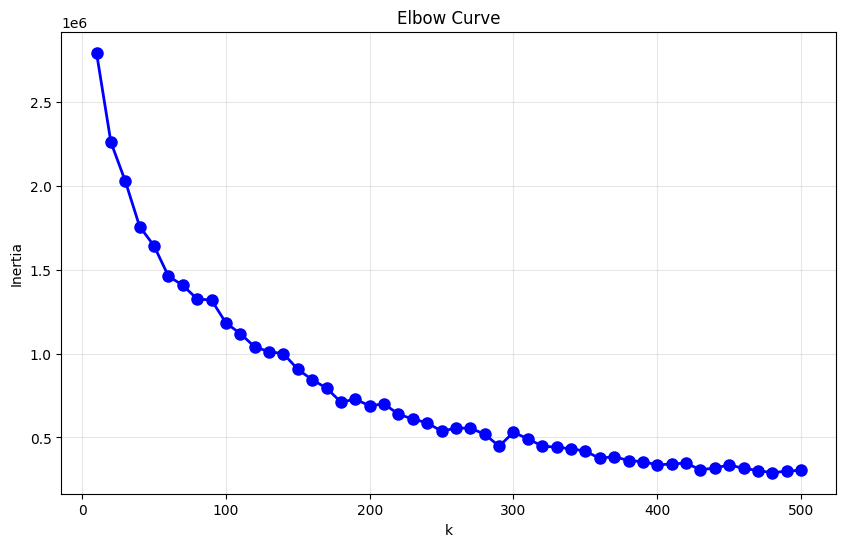

In [200]:
# try with different values of k:
inertias = []
k_range = range(10, 501, 10)
    
for k in k_range:
    print(f"k={k}...", end=' ')
    kmeans = MiniBatchKMeans(n_clusters=k, random_state=42, batch_size=2048)
    kmeans.fit(embeddings_no_outliers)
    inertias.append(kmeans.inertia_)
    print(f"inertia={kmeans.inertia_:.2f}")

# Plot
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Curve')
plt.grid(True, alpha=0.3)
plt.show()




In [202]:
print(f"Features shape: {embeddings_no_outliers.shape}")
print(f"Labels shape: {cluster_label_no_emb_outliers.shape}")
print(f"Unique clusters: {len(np.unique(cluster_label_no_emb_outliers))}")

Features shape: (220982, 150)
Labels shape: (220982,)
Unique clusters: 30


In [203]:
exp4_mod, exp4_lab = cluster_kmeans(embeddings_no_outliers, n_clusters=480, use_minibatch=True, random_state=42)

K-Means: k=480
Cluster sizes: min=13, max=2103


In [204]:
silhouette_score(embeddings_no_outliers, exp4_lab)

0.3094578981399536

# Reduce Overalap

### Preprocessing

In [88]:
top_n_categories = find_tail(cluster_df, 10)
top_n_categories = [i for i in top_n_categories if i not in ['en:null', 'en:undefined']]

124 categories are more than 90% out of 5477


In [91]:
keep_dist_cat = ["en:baby-foods", "en:fishes-and-their-products", "en:chocolates", "en:salads", "en:ice-creams-and-sorbets", "en:pastas", "en:bodybuilding-supplements", "en:canned-soups", "en:cheeses", "en:sodas"]
keep_dist_cat

['en:baby-foods',
 'en:fishes-and-their-products',
 'en:chocolates',
 'en:salads',
 'en:ice-creams-and-sorbets',
 'en:pastas',
 'en:bodybuilding-supplements',
 'en:canned-soups',
 'en:cheeses',
 'en:sodas']

In [92]:
def filter_if_all_present(cluster_df, allowed_categories):
    allowed_set = set(allowed_categories)

    def check_row(x):
        if pd.isna(x):
            return False
        cats = str(x).split(',')
        return all(cat.strip() in allowed_set for cat in cats)

    mask = cluster_df['categories_tags'].apply(check_row)
    return cluster_df[mask].copy()

def filter_if_one_present(cluster_df, allowed_categories):
    allowed_set = set(allowed_categories)

    def check_row(x):
        if pd.isna(x):
            return False
        cats = str(x).split(',')
        return any(cat.strip() in allowed_set for cat in cats)

    mask = cluster_df['categories_tags'].apply(check_row)
    return cluster_df[mask].copy()



In [93]:
cluster_df_dist_cats = filter_if_one_present(cluster_df, keep_dist_cat)
cluster_df_dist_cats.shape

(21695, 399)

In [94]:
cluster_df_top_n = filter_if_all_present(cluster_df, top_n_categories)
cluster_df_top_n.shape

(174470, 399)

In [95]:
cluster_df_dist_cats_emb, cluster_df_dist_cats_meta = extract_embeddings(cluster_df_dist_cats)
cluster_df_dist_cats_emb_umap_150, _ = reduce_dimensions_umap(cluster_df_dist_cats_emb, n_components=150, random_state=42)
# cluster_df_dist_cats_emb_umap_50, _ = reduce_dimensions_umap(cluster_df_dist_cats_emb, n_components=50, random_state=42)


Reducing from 383 to 150 dimensions using UMAP
UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Sun Nov 30 20:10:54 2025 Construct fuzzy simplicial set
Sun Nov 30 20:10:54 2025 Finding Nearest Neighbors
Sun Nov 30 20:10:54 2025 Building RP forest with 12 trees


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Sun Nov 30 20:10:55 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	 5  /  14
	Stopping threshold met -- exiting after 5 iterations
Sun Nov 30 20:10:56 2025 Finished Nearest Neighbor Search
Sun Nov 30 20:10:56 2025 Construct embedding


Epochs completed:   1%|            2/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  10%| █          21/200 [00:05]

... (15 outputs left out)

Epochs completed:  90%| █████████  181/200 [00:47]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:52]


Sun Nov 30 20:12:08 2025 Finished embedding
UMAP reduction complete: (21695, 150)


### Kmeans with Food Vectors - 150 and 50 dimensions

Text(0, 0.5, 'Silhouette Score')

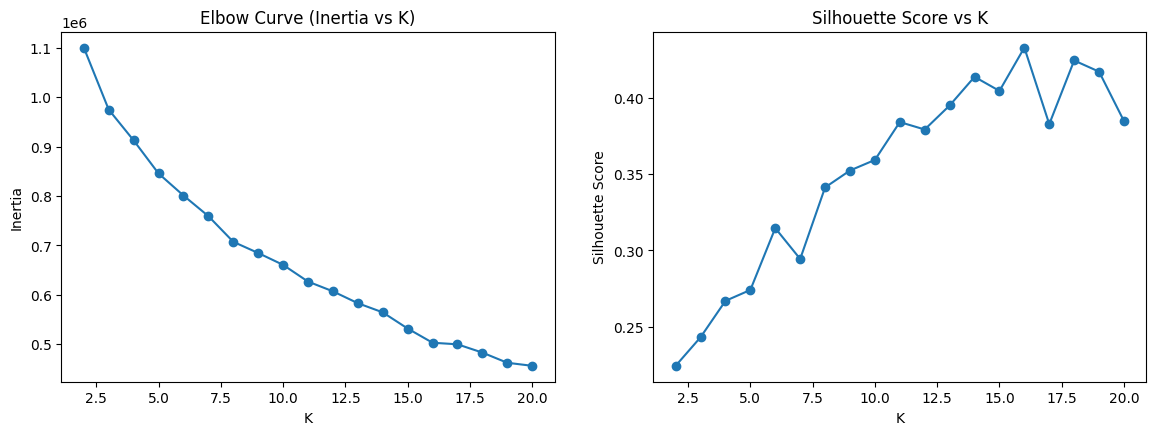

In [96]:
Ks = range(2, 21, 1) 
results_150_kmeans = {
    "k": [],
    "inertia": [],
    "silhouette": []
    # "davies_bouldin": [],
    # "calinski_harabasz": []
}

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(cluster_df_dist_cats_emb_umap_150)
    results_150_kmeans["k"].append(k)
    results_150_kmeans["inertia"].append(kmeans.inertia_)
    results_150_kmeans["silhouette"].append(silhouette_score(cluster_df_dist_cats_emb_umap_150, labels))

plt.figure(figsize=(14, 10))

# 1. Elbow curve (inertia)
plt.subplot(2, 2, 1)
plt.plot(results_150_kmeans["k"], results_150_kmeans["inertia"], marker='o')
plt.title("Elbow Curve (Inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")

# 2. Silhouette score
plt.subplot(2, 2, 2)
plt.plot(results_150_kmeans["k"], results_150_kmeans["silhouette"], marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")




In [98]:
#final model
k=16
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
labels = kmeans.fit_predict(cluster_df_dist_cats_emb_umap_150)
print(f"Cluster size: {k}")
print(f"Interia: {kmeans.inertia_}")
print(f"Silhouette score: {silhouette_score(cluster_df_dist_cats_emb_umap_150, labels)}")
print(f"Davies-Bouldin score: {davies_bouldin_score(cluster_df_dist_cats_emb_umap_150, labels)}")
print(f"Calinski-Harabasz score: {calinski_harabasz_score(cluster_df_dist_cats_emb_umap_150, labels)}")


Cluster size: 16
Interia: 502824.09375
Silhouette score: 0.432894229888916
Davies-Bouldin score: 1.3701253888872023
Calinski-Harabasz score: 2164.860107421875


In [54]:
pd.Series(labels).value_counts()

1     4865
3     3437
10    3224
2     3219
11    3062
4     1151
0      813
9      491
5      311
7      260
8      164
6      163
15     142
14     142
13     134
12     117
Name: count, dtype: int64

In [55]:
cluster_df_dist_cats_meta['cluster_id'] = labels
cluster_df_dist_cats_meta.head()

,product_name,categories_tags,nova_group,ingredients_text,ingredient_count,additives_n,nutriscore_score,monounsaturated-fat_100g,sugars_100g,polyunsaturated-fat_100g,sugar_fiber_ratio,carbohydrates_100g,fiber_100g,saturated-fat_100g,sodium_per_calorie,0,cluster_id
27,Rebuild 24,"en:dietary-supplements,en:bodybuilding-supplem...",4,supplement fact f serv per contain amount per ...,8,1.0,NaN,0.0,0.000000,0.0,NaN,0.000000,0.000000,0.000000,NaN,-0.045887,3
43,Dutch chocolate,"en:dietary-supplements,en:bodybuilding-supplem...",4,protein blend soy protein isol whey prote isol...,34,7.0,17.0,0.0,28.666668,0.0,2.082325,53.666668,13.666666,1.666667,0.001627,-0.056634,3
58,Bone broth powder,"en:dietary-supplements,en:bodybuilding-supplem...",4,beef bone broth powder cocoa powder alkali can...,7,2.0,NaN,0.0,9.090909,0.0,1.956947,18.181818,4.545454,0.000000,NaN,-0.061582,3
75,NaN,"en:dietary-supplements,en:bodybuilding-supplem...",4,soy protein crisp soy protein isol tapioca sta...,20,3.0,NaN,0.0,0.000000,0.0,NaN,0.000000,0.000000,0.000000,NaN,-0.067303,3
78,Isagenix,"en:dietary-supplements,en:bodybuilding-supplem...",4,phyto-isalean complext whole grain brown rice ...,49,3.0,12.0,0.0,11.290323,0.0,0.868271,35.483871,12.903226,2.419355,0.001516,0.000284,3


In [56]:
cluster_df_dist_cats_meta.to_csv("cluster_analysis_v4.csv")

Text(0, 0.5, 'Silhouette Score')

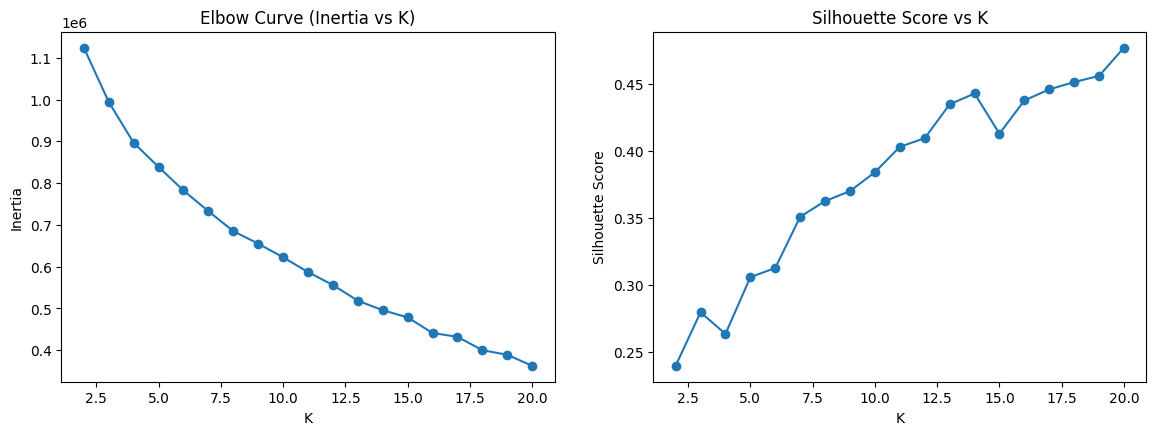

In [55]:
Ks = range(2, 21, 1) 
results_50_kmeans = {
    "k": [],
    "inertia": [],
    "silhouette": []
    # "davies_bouldin": [],
    # "calinski_harabasz": []
}

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(cluster_df_dist_cats_emb_umap_50)
    results_50_kmeans["k"].append(k)
    results_50_kmeans["inertia"].append(kmeans.inertia_)
    results_50_kmeans["silhouette"].append(silhouette_score(cluster_df_dist_cats_emb_umap_50, labels))

plt.figure(figsize=(14, 10))

# 1. Elbow curve (inertia)
plt.subplot(2, 2, 1)
plt.plot(results_50_kmeans["k"], results_50_kmeans["inertia"], marker='o')
plt.title("Elbow Curve (Inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")

# 2. Silhouette score
plt.subplot(2, 2, 2)
plt.plot(results_50_kmeans["k"], results_50_kmeans["silhouette"], marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")




### Specytral - doesnt work

In [59]:
from sklearn.cluster import SpectralClustering

Ks = range(2, 21, 1)
results_spectral = {
    "k": [],
    "silhouette": []
}

for k in Ks:
    print(f"k={k}...", end=' ')
    spectral = SpectralClustering(
        n_clusters=k, 
        random_state=42,
        affinity='nearest_neighbors', 
        n_neighbors=10,
        assign_labels='kmeans'
    )
    labels = spectral.fit_predict(cluster_df_dist_cats_emb_umap_150)
    
    sil = silhouette_score(cluster_df_dist_cats_emb_umap_150, labels)
    results_spectral["k"].append(k)
    results_spectral["silhouette"].append(sil)
    print(f"silhouette={sil:.4f}")

k=2... 

/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


silhouette=0.1728
k=3... 

/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


silhouette=-0.1580
k=4... 

/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


... (7 outputs left out)

/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


silhouette=-0.1896
k=9... 

/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


KeyboardInterrupt: 

In [74]:
cluster_df_dist_cats['ingredients_text']

27        supplement fact f serv per contain amount per ...
43        protein blend soy protein isol whey prote isol...
58        beef bone broth powder cocoa powder alkali can...
75        soy protein crisp soy protein isol tapioca sta...
78        phyto-isalean complext whole grain brown rice ...
                                ...                        
272772            organ brown rice flour organ millet flour
272780    hokkien noodl water wheat flour modifi tapioca...
272797    nonfat milk lactos high oleic safflow oil whey...
272804    rice flour whole wheat flour wheat starch cane...
272808    whey protein concentr grass-f undenatur collag...
Name: ingredients_text, Length: 21695, dtype: object

### Sentence vectors - Kmeans

In [86]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

In [84]:
ingredients_list = cluster_df_dist_cats['ingredients_text'].fillna('').tolist()
vectorizer = TfidfVectorizer(max_features=500, ngram_range=(1,2))
embeddings_tfidf = vectorizer.fit_transform(ingredients_list).toarray()

In [87]:
embeddings_norm = normalize(embeddings_tfidf, norm='l2')

In [90]:
embeddings_umap, _ = reduce_dimensions_umap(embeddings_norm, n_components=150)

Reducing from 500 to 150 dimensions using UMAP
UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Sat Nov 29 14:15:12 2025 Construct fuzzy simplicial set
Sat Nov 29 14:15:12 2025 Finding Nearest Neighbors
Sat Nov 29 14:15:12 2025 Building RP forest with 12 trees


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Sat Nov 29 14:15:13 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	 5  /  14
	Stopping threshold met -- exiting after 5 iterations
Sat Nov 29 14:15:15 2025 Finished Nearest Neighbor Search
Sat Nov 29 14:15:15 2025 Construct embedding


Epochs completed:   2%| ▏          4/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  10%| █          21/200 [00:05]

... (15 outputs left out)

Epochs completed:  90%| █████████  181/200 [00:50]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:56]


Sat Nov 29 14:16:32 2025 Finished embedding
UMAP reduction complete: (21695, 150)


In [89]:
kmeans = KMeans(n_clusters=10, random_state=42)
labels = kmeans.fit_predict(embeddings_umap)
sil = silhouette_score(embeddings_umap, labels)
print(f"Silhouette: {sil:.4f}")

Silhouette: 0.3168


2 0.23205718398094177
3 0.19169433414936066
4 0.2455289512872696
5 0.23844915628433228
6 0.23347365856170654
7 0.309162437915802
8 0.272448867559433
9 0.2746789753437042
10 0.29039379954338074
11 0.29331719875335693
12 0.30855661630630493
13 0.30393537878990173
14 0.3251039683818817
15 0.3433803915977478
16 0.2998562455177307
17 0.28536170721054077
18 0.31965628266334534
19 0.3450378179550171
20 0.28343284130096436


Text(0, 0.5, 'Silhouette Score')

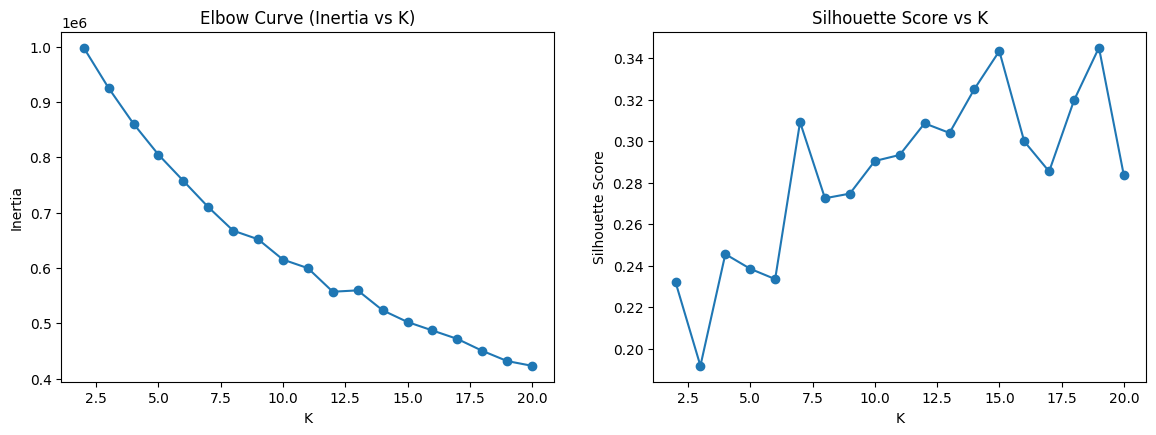

In [92]:
Ks = range(2, 21, 1) 
results_150_kmeans_tfid = {
    "k": [],
    "inertia": [],
    "silhouette": []
    # "davies_bouldin": [],
    # "calinski_harabasz": []
}

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(embeddings_umap)
    results_150_kmeans_tfid["k"].append(k)
    results_150_kmeans_tfid["inertia"].append(kmeans.inertia_)
    s = silhouette_score(embeddings_umap, labels)
    results_150_kmeans_tfid["silhouette"].append(s)
    print(k, end =" ")
    print(s)

plt.figure(figsize=(14, 10))

# 1. Elbow curve (inertia)
plt.subplot(2, 2, 1)
plt.plot(results_150_kmeans_tfid["k"], results_150_kmeans_tfid["inertia"], marker='o')
plt.title("Elbow Curve (Inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")

# 2. Silhouette score
plt.subplot(2, 2, 2)
plt.plot(results_150_kmeans_tfid["k"], results_150_kmeans_tfid["silhouette"], marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")




# Reduce Overlap - 2

In [ ]:
# 1.00 1.01 -> xyz
# 1.02 1.03 -> abc

In [ ]:
embeddings_array = cluster_df_dist_cats.iloc[:, 5:].values  
row_norms = np.linalg.norm(embeddings_array, axis=1)
percentiles = [10, 30, 50, 70, 90, 95]
sample_indices = []
for p in percentiles:
    target_norm = np.percentile(row_norms, p)
    
    # Find rows within ±2 percentile points of target
    lower = np.percentile(row_norms, p-2)
    upper = np.percentile(row_norms, p+2)
    
    # Sample 3-5 rows from this range
    mask = (row_norms >= lower) & (row_norms <= upper)
    candidates = np.where(mask)[0]
    # selected = np.random.choice(candidates, size=min(5, len(candidates)), replace=False)
    sample_indices.extend(candidates)


sampled_df = cluster_df_dist_cats.iloc[sample_indices]
sampled_embeddings = embeddings_array[sample_indices]
kmeans = KMeans(n_clusters=6, random_state=42)
labels = kmeans.fit_predict(sampled_embeddings)
sil = silhouette_score(sampled_embeddings, labels)
print(sil)

In [103]:
sil

0.14078842103481293

In [104]:
row_norms.min(), row_norms.max(), row_norms.std()

(np.float32(0.9999994), np.float32(1.0000005), np.float32(1.2960605e-07))

## the problem seems that embeddings are not seperate enough 

In [127]:
cluster_df.columns.tolist()

df = cluster_df.iloc[:, :15]
df.columns.tolist()

['product_name',
 'categories_tags',
 'nova_group',
 'ingredients_text',
 'ingredient_count',
 'additives_n',
 'nutriscore_score',
 'monounsaturated-fat_100g',
 'sugars_100g',
 'polyunsaturated-fat_100g',
 'sugar_fiber_ratio',
 'carbohydrates_100g',
 'fiber_100g',
 'saturated-fat_100g',
 'sodium_per_calorie']

In [128]:
print(df.shape)
df = df.dropna(axis = 0)

print(df.shape)
df.isna().sum()

(272809, 15)
(191868, 15)


product_name                0
categories_tags             0
nova_group                  0
ingredients_text            0
ingredient_count            0
additives_n                 0
nutriscore_score            0
monounsaturated-fat_100g    0
sugars_100g                 0
polyunsaturated-fat_100g    0
sugar_fiber_ratio           0
carbohydrates_100g          0
fiber_100g                  0
saturated-fat_100g          0
sodium_per_calorie          0
dtype: int64

In [131]:
from sklearn.decomposition import TruncatedSVD


In [129]:
numerical_cols = [
    'ingredient_count', 'additives_n', 'nutriscore_score',
    'monounsaturated-fat_100g', 'sugars_100g', 'polyunsaturated-fat_100g',
    'sugar_fiber_ratio', 'carbohydrates_100g', 'fiber_100g',
    'saturated-fat_100g', 'sodium_per_calorie'
]
scaler = StandardScaler()
numeric_data = scaler.fit_transform(cluster_df[numerical_cols])
vectorizer = TfidfVectorizer(max_features=1000)
text_embeddings = vectorizer.fit_transform(cluster_df['ingredients_text'])



In [132]:
svd = TruncatedSVD(n_components=50, random_state=42)
text_embeddings_reduced = svd.fit_transform(text_embeddings)


In [139]:
combined_features = np.hstack([numeric_data, text_embeddings_reduced])


In [140]:
combined_features = np.nan_to_num(combined_features, nan=0.0, posinf=0.0, neginf=0.0)


In [147]:
k=30
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
labels = kmeans.fit_predict(combined_features)

In [148]:
print(silhouette_score(combined_features, labels))

0.17404113827171266


5 completed
10 completed
15 completed
20 completed
25 completed
30 completed
35 completed
40 completed
45 completed
50 completed
55 completed
60 completed
65 completed
70 completed
75 completed
80 completed
85 completed
90 completed
95 completed
100 completed


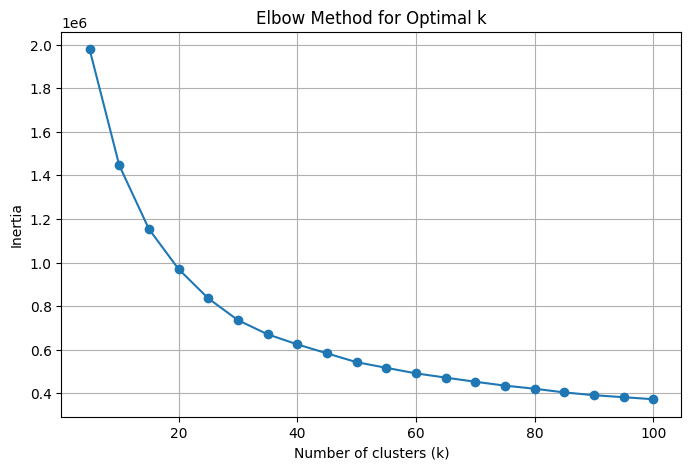

In [144]:
results = {
    'k_val': [],
    'inertia': []
}
for k in range(5, 101, 5):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(combined_features)
    results['k_val'].append(k)
    results['inertia'].append(kmeans.inertia_)
    print(f"{k} completed")


plt.figure(figsize=(8,5))
plt.plot(results['k_val'], results['inertia'], marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [146]:
pd.DataFrame(results)

,k_val,inertia
0,5,1.978546e+06
1,10,1.445914e+06
2,15,1.153552e+06
3,20,9.698304e+05
4,25,8.355485e+05
5,30,7.356044e+05
6,35,6.707351e+05
7,40,6.245040e+05
8,45,5.833565e+05
9,50,5.426925e+05


# Final Updates

In [57]:
keep_dist_cat = ["en:baby-foods", "en:fishes-and-their-products", "en:chocolates", "en:salads", "en:ice-creams-and-sorbets", "en:pastas", "en:bodybuilding-supplements", "en:canned-soups", "en:cheeses", "en:sodas", "en:breakfast-cereals", "en:waters"]
keep_dist_cat

['en:baby-foods',
 'en:fishes-and-their-products',
 'en:chocolates',
 'en:salads',
 'en:ice-creams-and-sorbets',
 'en:pastas',
 'en:bodybuilding-supplements',
 'en:canned-soups',
 'en:cheeses',
 'en:sodas',
 'en:breakfast-cereals',
 'en:waters']

In [59]:
clean_df = filter_if_one_present(cluster_df, keep_dist_cat)

In [70]:
def find_category_counts(clean_df, keep_dist_cat):
    category_counts = {}

    for category in keep_dist_cat:

        count = clean_df['categories_tags'].str.contains(category, na=False).sum()
        category_counts[category] = count


    counts_df = pd.DataFrame(list(category_counts.items()), columns=['Category', 'Count'])
    counts_df = counts_df.sort_values('Count', ascending=False)

    # print(counts_df)
    # print(f"Total rows in filtered data: {len(clean_df)}")
    return counts_df


In [62]:

category_counts = {}

for category in keep_dist_cat:

    count = clean_df['categories_tags'].str.contains(category, na=False).sum()
    category_counts[category] = count


counts_df = pd.DataFrame(list(category_counts.items()), columns=['Category', 'Count'])
counts_df = counts_df.sort_values('Count', ascending=False)

print(counts_df)
print(f"Total rows in filtered data: {len(clean_df)}")

                        Category  Count
5                      en:pastas   5462
8                     en:cheeses   4635
9                       en:sodas   3783
11                     en:waters   2537
7                en:canned-soups   2188
10          en:breakfast-cereals   1857
6    en:bodybuilding-supplements   1550
4      en:ice-creams-and-sorbets    984
2                  en:chocolates    840
1   en:fishes-and-their-products    818
3                      en:salads    770
0                  en:baby-foods    679
Total rows in filtered data: 26041


In [63]:
def stratified_downsample(df, category_list, cap, seed=42):
    rng = np.random.RandomState(seed)
    final_parts = []

    for cat in category_list:

        cat_mask = df['categories_tags'].str.contains(cat, na=False)
        cat_df = df[cat_mask]


        if len(cat_df) > cap:
            idx = rng.choice(cat_df.index, cap, replace=False)
            cat_df = cat_df.loc[idx]

        final_parts.append(cat_df)

    return pd.concat(final_parts).drop_duplicates().reset_index(drop=True)


balanced_df = stratified_downsample(clean_df, keep_dist_cat, cap=1500)
print(balanced_df.shape)


(14082, 399)


In [64]:
balanced_df_emb, balanced_df_meta = extract_embeddings(balanced_df)
balanced_df_emb_umap_150, _ = reduce_dimensions_umap(balanced_df_emb, n_components=150, random_state=42)

Reducing from 383 to 150 dimensions using UMAP
UMAP(angular_rp_forest=True, metric='cosine', n_components=150, n_jobs=1, random_state=42, verbose=True)
Sun Nov 30 19:55:26 2025 Construct fuzzy simplicial set
Sun Nov 30 19:55:26 2025 Finding Nearest Neighbors
Sun Nov 30 19:55:26 2025 Building RP forest with 11 trees


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Sun Nov 30 19:55:27 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	 5  /  14
	Stopping threshold met -- exiting after 5 iterations
Sun Nov 30 19:55:28 2025 Finished Nearest Neighbor Search
Sun Nov 30 19:55:28 2025 Construct embedding


Epochs completed:   2%| ▎          5/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  11%| █          22/200 [00:03]

... (15 outputs left out)

Epochs completed:  91%| █████████  182/200 [00:27]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:30]


Sun Nov 30 19:56:07 2025 Finished embedding
UMAP reduction complete: (14082, 150)


Text(0, 0.5, 'Silhouette Score')

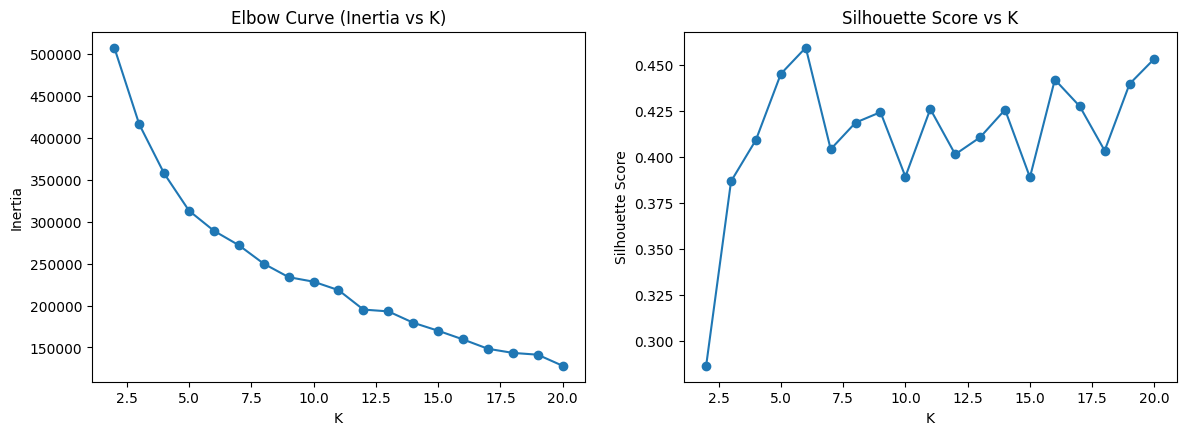

In [66]:
Ks = range(2, 21, 1) 
results_150_kmeans = {
    "k": [],
    "inertia": [],
    "silhouette": []
}

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(balanced_df_emb_umap_150)
    results_150_kmeans["k"].append(k)
    results_150_kmeans["inertia"].append(kmeans.inertia_)
    results_150_kmeans["silhouette"].append(silhouette_score(balanced_df_emb_umap_150, labels))

plt.figure(figsize=(14, 10))

# 1. Elbow curve (inertia)
plt.subplot(2, 2, 1)
plt.plot(results_150_kmeans["k"], results_150_kmeans["inertia"], marker='o')
plt.title("Elbow Curve (Inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")

# 2. Silhouette score
plt.subplot(2, 2, 2)
plt.plot(results_150_kmeans["k"], results_150_kmeans["silhouette"], marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")




In [68]:
pd.DataFrame(results_150_kmeans)

,k,inertia,silhouette
0,2,507449.031250,0.286408
1,3,416065.843750,0.386673
2,4,357448.875000,0.409174
3,5,312974.500000,0.445055
4,6,289052.312500,0.459307
5,7,271856.656250,0.404095
6,8,249832.093750,0.418564
7,9,233798.937500,0.424245
8,10,228397.718750,0.389176
9,11,218335.875000,0.425949


In [72]:
find_category_counts(balanced_df, keep_dist_cat)

,Category,Count
10,en:breakfast-cereals,1498
6,en:bodybuilding-supplements,1491
8,en:cheeses,1491
9,en:sodas,1481
5,en:pastas,1480
7,en:canned-soups,1470
11,en:waters,1169
4,en:ice-creams-and-sorbets,983
2,en:chocolates,834
1,en:fishes-and-their-products,799


In [77]:
df_new = pd.concat([balanced_df_meta, pd.DataFrame(balanced_df_emb_umap_150)], axis=1)
df_new = stratified_downsample(df_new, keep_dist_cat, cap=600)
find_category_counts(df_new, keep_dist_cat)

,Category,Count
9,en:sodas,609
11,en:waters,604
1,en:fishes-and-their-products,601
4,en:ice-creams-and-sorbets,601
5,en:pastas,601
6,en:bodybuilding-supplements,601
8,en:cheeses,601
10,en:breakfast-cereals,601
0,en:baby-foods,600
2,en:chocolates,600


In [78]:
df_new_emb, df_new_meta = extract_embeddings(df_new)

Text(0, 0.5, 'Silhouette Score')

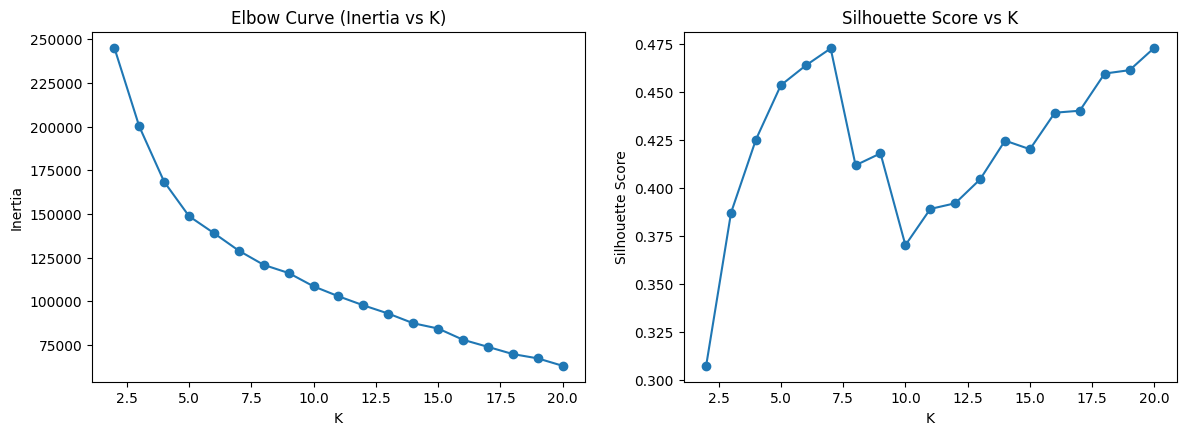

In [79]:
Ks = range(2, 21, 1) 
results_150_kmeans = {
    "k": [],
    "inertia": [],
    "silhouette": []
}

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = kmeans.fit_predict(df_new_emb)
    results_150_kmeans["k"].append(k)
    results_150_kmeans["inertia"].append(kmeans.inertia_)
    results_150_kmeans["silhouette"].append(silhouette_score(df_new_emb, labels))

plt.figure(figsize=(14, 10))

# 1. Elbow curve (inertia)
plt.subplot(2, 2, 1)
plt.plot(results_150_kmeans["k"], results_150_kmeans["inertia"], marker='o')
plt.title("Elbow Curve (Inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")

# 2. Silhouette score
plt.subplot(2, 2, 2)
plt.plot(results_150_kmeans["k"], results_150_kmeans["silhouette"], marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette Score")

Reducing from 383 to 2 dimensions using UMAP


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(angular_rp_forest=True, metric='cosine', n_jobs=1, random_state=42, verbose=True)
Mon Dec  1 01:26:53 2025 Construct fuzzy simplicial set
Mon Dec  1 01:26:53 2025 Finding Nearest Neighbors
Mon Dec  1 01:26:53 2025 Building RP forest with 12 trees
Mon Dec  1 01:26:54 2025 NN descent for 14 iterations
	 1  /  14
	 2  /  14
	 3  /  14
	 4  /  14
	 5  /  14
	Stopping threshold met -- exiting after 5 iterations
Mon Dec  1 01:26:56 2025 Finished Nearest Neighbor Search
Mon Dec  1 01:26:56 2025 Construct embedding


/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/utkarshmaheshwari/opt/anaconda3/envs/nutrilens/lib/python3.10/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
Epochs completed:   3%| ▎

	completed  0  /  200 epochs


Epochs completed:  12%| █▏         23/200 [00:01]

... (15 outputs left out)

Epochs completed:  92%| █████████▏ 183/200 [00:14]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:15]


Mon Dec  1 01:27:19 2025 Finished embedding
UMAP reduction complete: (21695, 2)


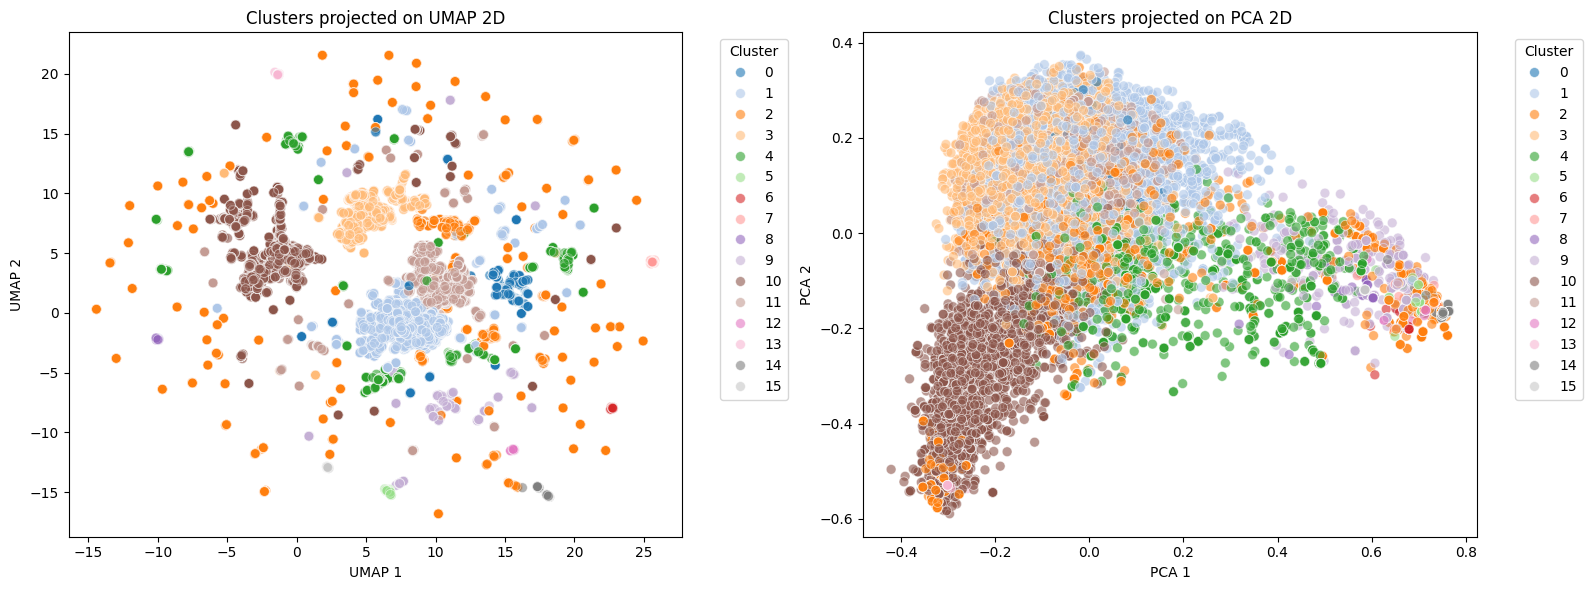

In [99]:
from sklearn.decomposition import PCA

# Project to 2D for visualization
X_umap_2d, _ = reduce_dimensions_umap(cluster_df_dist_cats_emb, n_components=2, random_state=42)
pca_2d = PCA(n_components=2, random_state=42).fit_transform(cluster_df_dist_cats_emb)

# Use your best KMeans labels
labels_best = labels  # from k=16 KMeans on 150D UMAP embeddings

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# UMAP 2D
sns.scatterplot(
    x=X_umap_2d[:,0], y=X_umap_2d[:,1],
    hue=labels_best, palette='tab20', alpha=0.6, s=50,
    ax=axes[0]
)
axes[0].set_title("Clusters projected on UMAP 2D")
axes[0].set_xlabel("UMAP 1")
axes[0].set_ylabel("UMAP 2")
axes[0].legend(title="Cluster", bbox_to_anchor=(1.05, 1))

# PCA 2D
sns.scatterplot(
    x=pca_2d[:,0], y=pca_2d[:,1],
    hue=labels_best, palette='tab20', alpha=0.6, s=50,
    ax=axes[1]
)
axes[1].set_title("Clusters projected on PCA 2D")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")
axes[1].legend(title="Cluster", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()
